# Running ELAsTiCC light curves through SELDON with Hyrax on DeltaAI

This notebook runs a sample of the [ELAsTiCC2](https://portal.nersc.gov/cfs/lsst/DESC_TD_PUBLIC/ELASTICC/)
training light curves through a trained SELDON model, using Hyrax's `infer` verb and
`hyrax_seldon`'s model (`HyraxSeldon`) and dataset (`ElasticcParquetDataset`), on one GPU of
NCSA's [DeltaAI](https://docs.ncsa.illinois.edu/systems/deltaai/en/latest/index.html).

It is self-contained: the setup steps you do once on DeltaAI are in this first part, as shell
commands to run in a DeltaAI terminal. The code cells after that run on a GPU node.

What it does:

1. Picks a sample of ELAsTiCC objects (a fixed number per class) from the parquet files that
   `data/download_elasticc.py` makes, and writes them to one parquet file.
2. Runs `h.infer()` with `HyraxSeldon` loaded from a SELDON training run's Lightning checkpoint.
3. Reads the results back and compares SELDON's class predictions with the true ELAsTiCC classes.

Running the whole notebook on the default sample takes a few minutes of one GPU. Nothing in it
needs more than one GPU.

## Part 1: One-time setup on DeltaAI

Run these in a terminal on a DeltaAI login node (`ssh <username>@dtai-login.delta.ncsa.illinois.edu`).
The login nodes are shared: use them for installing software and moving files, and leave
model runs to the GPU nodes (part 2).

### 1a. Pick an allocation and a place for large files

```bash
accounts                         # your DeltaAI accounts, e.g. bgud-dtai-gh: this is the Slurm --account
quota                            # your home quota (~100 GB) and your allocations' /projects and /work space
```

Your home directory is small, so put the data (7.4 GiB download, ~8 GB extracted) in your
allocation's project space, for example `/projects/<allocation>/$USER`. Below,
`<allocation>` is the short name of your account (`bgud` for `bgud-dtai-gh`).

### 1b. A Python environment with hyrax_seldon

DeltaAI's nodes are aarch64 (NVIDIA Grace Hopper). A conda-forge Miniconda/Miniforge plus pip
works; the PyPI `torch` wheels for aarch64 include CUDA.

```bash
# Miniforge (conda-forge only) in your home directory, if you don't have conda already
curl -LO https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-aarch64.sh
bash Miniforge3-Linux-aarch64.sh -b -p ~/miniforge3
source ~/miniforge3/etc/profile.d/conda.sh

conda create -y -n hyrax-seldon python=3.12
conda activate hyrax-seldon

git clone https://github.com/lincc-frameworks/hyrax_seldon.git
pip install -e './hyrax_seldon[dev]'   # pulls in hyrax, hyrax_alerts, SELDON (seldon_core), torch
pip install ipykernel matplotlib

# Make the environment a Jupyter kernel, so Open OnDemand's JupyterLab can use it
python -m ipykernel install --user --name hyrax-seldon --display-name "hyrax-seldon"
```

If you already have editable checkouts of `hyrax`, `hyrax_alerts` and SELDON in the environment,
install `hyrax_seldon` with `pip install --no-deps -e ./hyrax_seldon` so its git dependencies don't
replace them.

### 1c. The SELDON checkpoint

The model is a SELDON training run (`SELDONEnergyClassifierDictModel`). Unpack the run you were
given, e.g. the SELDON 2.0 `..._roman_elasticc` tarball, anywhere; what matters is the run
directory, which holds:

```
<run_dir>/hparams.yaml                 # the run config: architecture, preprocessing, statistics, classes
<run_dir>/checkpoints/<name>.ckpt      # the Lightning checkpoint
```

Use it as it is. `hparams.yaml` holds absolute paths from the machine SELDON was trained on
(for the filter transmission curves); `hyrax_seldon` points them at the copies installed with
SELDON, so the file does not need editing.

### 1d. Download and convert ELAsTiCC2 (once)

`hyrax_seldon` has a script that downloads the ELAsTiCC2 training sample (7.4 GiB), extracts it
and converts it to the parquet schema SELDON reads, one file per class. Converting only the
first of each class's 40 FITS files is plenty for this notebook (a few thousand objects per
class):

```bash
python hyrax_seldon/data/download_elasticc.py \
    --data-dir /projects/<allocation>/$USER/elasticc2_train --files-per-class 1 --workers 4
```

This is downloading and file conversion, not model work. It took about 10 minutes on DeltaAI,
mostly decompressing the archive, and is safe to rerun: finished steps are skipped. The output is
`/projects/<allocation>/$USER/elasticc2_train/parquet_1_files_per_class/<class>.parquet`.

## Part 2: Run this notebook on one GPU

Either way below, you get one GH200 GPU on a `ghx4` node. The `ghx4` partition is charged at
1x; `ghx4-interactive` is charged at 2x and limited to 2 hours, so prefer `ghx4`.

**Option A: JupyterLab in Open OnDemand.** Go to <https://gh-ondemand.delta.ncsa.illinois.edu/>,
choose *Interactive Apps → Jupyter Lab*, and fill in the form:

| Field | Value |
|---|---|
| Name of account | your account from `accounts`, e.g. `bgud-dtai-gh` |
| Partition | `ghx4` |
| Duration of job | `00:30:00` (raise it if you raise `N_PER_CLASS`) |
| Number of CPUs | `16` |
| Amount of RAM | `64g` |
| Number of GPUs | `1` |

When the session starts, open this notebook, choose the **hyrax-seldon** kernel, edit the
settings cell below, and run all cells. End the session from *My Interactive Sessions* when
you are done, so the GPU stops being charged.

**Option B: a batch job.** Save this as `run_notebook.sbatch` next to the notebook, edit the
account and the conda lines, and `sbatch run_notebook.sbatch`. The executed notebook, with its
outputs, replaces the original.

```bash
#!/bin/bash
#SBATCH --account=bgud-dtai-gh
#SBATCH --partition=ghx4
#SBATCH --nodes=1
#SBATCH --ntasks-per-node=1
#SBATCH --cpus-per-task=16
#SBATCH --mem=64g
#SBATCH --gpus-per-node=1
#SBATCH --time=00:30:00
#SBATCH --job-name=elasticc-seldon
#SBATCH --output=%x-%j.out

source ~/miniforge3/etc/profile.d/conda.sh
conda activate hyrax-seldon
jupyter nbconvert --to notebook --execute --inplace \
    --ExecutePreprocessor.timeout=-1 --ExecutePreprocessor.kernel_name=hyrax-seldon \
    elasticc_on_deltaai.ipynb
```

Check on it with `squeue -u $USER`, and see what it cost with
`sacct -j <jobid> -o JobID,State,Elapsed,AllocTRES`.

## Settings

Edit these for your account and files. Each one can also be set from an environment variable
of the same name, which is handy with option B.

In [1]:
import os
from pathlib import Path

USER = os.environ["USER"]
ALLOCATION = os.environ.get("ALLOCATION", "bgud")

# The parquet files made by data/download_elasticc.py --files-per-class 1 (part 1d).
ELASTICC_PARQUET_DIR = Path(
    os.environ.get(
        "ELASTICC_PARQUET_DIR",
        f"/projects/{ALLOCATION}/{USER}/elasticc2_train/parquet_1_files_per_class",
    )
)

# The SELDON training run directory: hparams.yaml and checkpoints/*.ckpt (part 1c).
SELDON_RUN_DIR = Path(
    os.environ.get(
        "SELDON_RUN_DIR",
        f"/u/{USER}/hyrax-seldon-workspace/seldon_checkpoint/logs/"
        "SELDON_2.0_S_E_UQ_C_with_transmission_delta_refactored_l6_b2048_e256_o256_d256_roman_elasticc_backup/version_0",
    )
)

# Where this notebook writes the sample parquet and Hyrax's results.
WORK_DIR = Path(os.environ.get("WORK_DIR", f"/projects/{ALLOCATION}/{USER}/elasticc_seldon"))

# How many objects to take from each ELAsTiCC class, and the random seed for picking them.
N_PER_CLASS = int(os.environ.get("N_PER_CLASS", 200))
SEED = int(os.environ.get("SEED", 0))

# Hyrax's data loader: objects per batch and loader worker processes.
BATCH_SIZE = int(os.environ.get("BATCH_SIZE", 512))
NUM_WORKERS = int(os.environ.get("NUM_WORKERS", 8))

HPARAMS = SELDON_RUN_DIR / "hparams.yaml"
(CHECKPOINT,) = sorted((SELDON_RUN_DIR / "checkpoints").glob("*.ckpt"))
WORK_DIR.mkdir(parents=True, exist_ok=True)
print(f"checkpoint: {CHECKPOINT}\ndata:       {ELASTICC_PARQUET_DIR}\nwork dir:   {WORK_DIR}")

checkpoint: /u/mtauraso/hyrax-seldon-workspace/seldon_checkpoint/logs/SELDON_2.0_S_E_UQ_C_with_transmission_delta_refactored_l6_b2048_e256_o256_d256_roman_elasticc_backup/version_0/checkpoints/epoch=1086-val_loss=1.18.ckpt
data:       /projects/bgud/mtauraso/elasticc2_train/parquet_1_files_per_class
work dir:   /projects/bgud/mtauraso/elasticc_seldon


## Check the GPU

Hyrax runs on the GPU when PyTorch can see one. On a login node, or in a session without a GPU,
this cell stops the notebook rather than running SELDON on the CPU.

In [2]:
import subprocess
import warnings

import matplotlib.pyplot as plt
import torch

# Hyrax's data loader forks worker processes after opening its result store; lance warns about
# that once per worker. Silence those, and PyTorch's warning about read-only arrays.
warnings.filterwarnings("ignore", message=".*fork")
warnings.filterwarnings("ignore", message="The given NumPy array is not writable")
plt.rcParams["figure.dpi"] = 72

print(subprocess.run(["hostname"], capture_output=True, text=True).stdout.strip())
assert torch.cuda.is_available(), "No GPU visible: run this notebook in a GPU job (part 2)."
print(torch.cuda.get_device_name(0), f"(torch {torch.__version__}, CUDA {torch.version.cuda})")

gh013.hsn.cm.delta.internal.ncsa.edu
NVIDIA GH200 120GB (torch 2.15.0+cu132, CUDA 13.2)


## Pick a sample of ELAsTiCC objects

Each class file holds every object from that class's first FITS file. From each class, this
takes `N_PER_CLASS` objects at random, among those SELDON can use: objects with at least
`min_points` detections (unsaturated points flagged as detections; 32 for this run). SELDON's
own data loader drops the rest, so the model never saw such light curves in training.

The sample keeps `ELASTICC_class` and the class SELDON's run maps it to (`SELDON_class`), which
is `None` for ELAsTiCC classes the run did not train on (variable stars, AGN, ...). Hyrax only
reads the light-curve columns and `SNID`.

In [3]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from hyrax_seldon import _seldon

run_config = _seldon.load_yaml(HPARAMS)
dataset_config = run_config["dataset"]["config"]
MIN_POINTS = dataset_config["min_points"]
CLASS_MAP = dataset_config["class_map"]  # SELDON class name -> class index the model predicts
CLASS_NAMES = [name for name, _ in sorted(CLASS_MAP.items(), key=lambda item: item[1])]


def seldon_class(elasticc_class):
    # The run config's class_mapping groups ELAsTiCC models into SELDON classes.
    name = dataset_config["class_mapping"].get(elasticc_class, elasticc_class)
    return name if name in CLASS_MAP else None


def n_detections(photflag):
    # As SELDON's load_data counts them: detection flags (4096 | 2048) on unsaturated points.
    flags = np.asarray(photflag).astype(np.uint32)
    return int(np.count_nonzero(((flags & 6144) != 0) & ((flags & 1024) == 0)))


columns = ["SNID", "MJD", "FLUXCAL", "FLUXCALERR", "BAND", "PHOTFLAG", "ELASTICC_class"]
rng = np.random.default_rng(SEED)
samples, summary = [], []
for path in sorted(ELASTICC_PARQUET_DIR.glob("*.parquet")):
    table = pq.read_table(path, columns=columns).to_pandas()
    usable = table[[n_detections(f) >= MIN_POINTS for f in table["PHOTFLAG"]]]
    chosen = usable.iloc[np.sort(rng.choice(len(usable), min(N_PER_CLASS, len(usable)), replace=False))]
    samples.append(chosen)
    summary.append((path.stem, seldon_class(path.stem), len(table), len(usable), len(chosen)))

sample = pd.concat(samples, ignore_index=True)
sample["SELDON_class"] = sample["ELASTICC_class"].map(seldon_class)
assert sample["SNID"].is_unique

SAMPLE_PARQUET = WORK_DIR / f"elasticc_sample_{N_PER_CLASS}_per_class.parquet"
sample.to_parquet(SAMPLE_PARQUET)

summary = pd.DataFrame(summary, columns=["ELASTICC_class", "SELDON_class", "objects", "usable", "sampled"])
print(f"{len(sample)} objects from {len(summary)} classes -> {SAMPLE_PARQUET}")
summary

2985 objects from 32 classes -> /projects/bgud/mtauraso/elasticc_seldon/elasticc_sample_200_per_class.parquet


,ELASTICC_class,SELDON_class,objects,usable,sampled
0,CART,NaN,307,19,19
1,CLAGN,NaN,2711,1645,200
2,Cepheid,NaN,484,431,200
3,EB,NaN,2369,880,200
4,ILOT,ILOT,264,51,51
5,KN_B19,NaN,34,0,0
6,KN_K17,NaN,115,0,0
7,Mdwarf-flare,NaN,70,0,0
8,PISN,PISN,2242,857,200
9,RRL,NaN,496,491,200


## Run SELDON with Hyrax

The Hyrax configuration names:

- the model, `hyrax_seldon.models.seldon.HyraxSeldon`, and the SELDON run config it is built
  from (`[model.HyraxSeldon].seldon_config`, the run's `hparams.yaml`);
- the weights, `[infer].model_weights_file`: the run's Lightning `.ckpt`, which `HyraxSeldon`
  loads directly;
- the data, `[data_request.infer.data]`: `ElasticcParquetDataset` over the sample, with
  `SNID` as the object id and the five per-point light-curve fields. The group must be named
  `data`.

`HyraxSeldon.prepare_inputs` hands each batch to SELDON's own data module and preprocessor,
with the run's statistics, so the light curves are prepared exactly as SELDON prepares new data.

In [4]:
import json
import time

from hyrax import Hyrax

RESULTS_DIR = WORK_DIR / "results"
config_file = WORK_DIR / "infer_config.toml"
config_file.write_text(f'''
[general]
results_dir = "{RESULTS_DIR}"

[data_loader]
batch_size = {BATCH_SIZE}
num_workers = {NUM_WORKERS}

[model]
name = "hyrax_seldon.models.seldon.HyraxSeldon"

[model.HyraxSeldon]
seldon_config = "{HPARAMS}"

[infer]
model_weights_file = "{CHECKPOINT}"

[data_request.infer.data]
dataset_class = "hyrax_seldon.datasets.elasticc_parquet.ElasticcParquetDataset"
data_location = "{SAMPLE_PARQUET}"
primary_id_field = "SNID"
fields = {json.dumps(["MJD", "FLUXCAL", "FLUXCALERR", "BAND", "PHOTFLAG"])}
''')

h = Hyrax(config_file=config_file)
start = time.perf_counter()
results = h.infer()
elapsed = time.perf_counter() - start
print(f"{len(results)} objects in {elapsed:.0f} s ({len(results) / elapsed:.0f} objects/s)")

All migrations complete. Your configuration file is now up to date with the latest schema. The runtime config saved in the output directory will reflect the new schema, and your original config file will remain unchanged on disk.


Runtime config contains key or section 'num_workers' which has no default defined. All configuration keys and sections must be defined in /u/mtauraso/hyrax-seldon-workspace/hyrax/src/hyrax/hyrax_default_config.toml


[2026-11-11 08:00:00,202 hyrax.models.model_registry:INFO] Setting model's self.optimizer from config: torch.optim.SGD with arguments: {'lr': 0.01, 'momentum': 0.9}.


[2026-11-11 08:00:00,204 hyrax.models.model_registry:INFO] Setting model's self.criterion from config: torch.nn.CrossEntropyLoss with default arguments.


[2026-11-11 08:00:00,204 hyrax.models.model_registry:INFO] Setting model's self.scheduler from config: torch.optim.lr_scheduler.ExponentialLR
with arguments: {'gamma': 1}.


[2026-11-11 08:00:00,204 hyrax.verbs.infer:INFO] Inference model: HyraxSeldon


... (6 outputs left out)

[2026-11-11 08:00:11,207 hyrax.datasets.result_dataset:INFO] Optimizing Lance table after 6 batches


[2026-11-11 08:00:11,837 hyrax.datasets.result_dataset:INFO] Lance table optimization complete


[2026-11-11 08:00:11,842 hyrax.verbs.infer:INFO] Inference Complete.


2985 objects in 19 s (157 objects/s)


## Read the results

Hyrax wrote one row per object to a results directory under `RESULTS_DIR`, with every output
of SELDON's `forward()`. The ones used below:

- `z_mean`, `z_sigma`: the posterior over SELDON's 6-dimensional latent space;
- `reconstructed`, `error`: the decoder's light curve, and its uncertainty, at each observed
  point (in time order, `max_length` entries, real where `pad_mask_full` is true), in SELDON's
  normalized flux units. A light curve with more than `max_length` points is encoded and
  reconstructed over a window of `max_length` of them (see sanity check 2). In evaluation mode the decoder is fed `z_mean`, so these are
  deterministic;
- `class_idx`: the class SELDON predicts, from one *sample* of the posterior, so it can change
  from run to run;
- `elbo`: despite its name, the KL divergence of the posterior from the prior;
- `short_lightcurve`: the object has fewer than `min_points` detections (none do here; the
  sample excludes them).

The outputs are read into arrays and joined to the sample by `SNID`.

In [5]:
KEYS = [
    "z_mean",
    "z_sigma",
    "class_idx",
    "elbo",
    "reconstructed",
    "error",
    "pad_mask_full",
    "short_lightcurve",
]
ids = np.array(results.ids()).astype(np.int64)
rows = results[np.arange(len(results))]
outputs = {key: np.stack([row[key] for row in rows]) for key in KEYS}
row_of = {snid: i for i, snid in enumerate(ids)}  # SNID -> row of `outputs`
print({key: value.shape for key, value in outputs.items()})

frame = pd.DataFrame(
    {
        "SNID": ids,
        "class_idx": outputs["class_idx"].reshape(len(ids)).astype(int),
        "elbo": outputs["elbo"].reshape(len(ids)),
    }
)
frame = sample[["SNID", "ELASTICC_class", "SELDON_class"]].merge(frame, on="SNID", validate="1:1")
frame["predicted"] = [CLASS_NAMES[i] if i < len(CLASS_NAMES) else f"index {i}" for i in frame["class_idx"]]
frame.head()

{'z_mean': (2985, 6), 'z_sigma': (2985, 6), 'class_idx': (2985,), 'elbo': (2985,), 'reconstructed': (2985, 256, 1), 'error': (2985, 256, 1), 'pad_mask_full': (2985, 256), 'short_lightcurve': (2985,)}


,SNID,ELASTICC_class,SELDON_class,class_idx,elbo,predicted
0,17935982,CART,NaN,2,20.600840,SLSN
1,49931418,CART,NaN,8,19.392920,SNIb/c
2,22064833,CART,NaN,2,19.523350,SLSN
3,69631341,CART,NaN,5,20.438370,SNIIn
4,47717333,CART,NaN,2,21.813129,SLSN


## Sanity checks

Before reading anything into the results, check that the model is doing what it should on
this data, rather than producing numbers that merely have the right shapes.

### 1. Every output is finite, and the latents differ between objects

A model that has collapsed (or weights that failed to load) tends to give the same latent for
every input; SELDON's `z_mean` should spread out across objects, more than the posterior
width `z_sigma` of any one object.

In [6]:
valid = outputs["pad_mask_full"].astype(bool)
checks = {
    "all z_mean, z_sigma, elbo finite": all(
        np.isfinite(outputs[k]).all() for k in ["z_mean", "z_sigma", "elbo"]
    ),
    "reconstructed, error finite at real points": bool(
        np.isfinite(outputs["reconstructed"][..., 0][valid]).all()
        and np.isfinite(outputs["error"][..., 0][valid]).all()
    ),
    "no short light curves": not outputs["short_lightcurve"].any(),
    "class_idx in range": bool((outputs["class_idx"] < len(CLASS_NAMES)).all()),
}
spread = outputs["z_mean"].std(axis=0)
width = np.median(outputs["z_sigma"], axis=0)
print("z_mean std across objects:  ", np.round(spread, 3))
print("median z_sigma per dimension:", np.round(width, 3))
checks["latents spread more than posterior width"] = bool((spread > width).all())
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(checks.values())

z_mean std across objects:   [1.164 0.832 0.713 0.592 0.72  0.857]
median z_sigma per dimension: [0.033 0.012 0.022 0.033 0.027 0.051]
PASS  all z_mean, z_sigma, elbo finite
PASS  reconstructed, error finite at real points
PASS  no short light curves
PASS  class_idx in range
PASS  latents spread more than posterior width


### 2. Hyrax gives what a direct call to SELDON gives, object by object

Hyrax's data loader read the sample in file order, `BATCH_SIZE` objects at a time. Replay those
same batches without Hyrax: prepare each with SELDON's own data module and the run's statistics
(`hyrax_seldon._seldon.preprocess`), run the model on it directly, and compare with what Hyrax
saved for the same `SNID`s. Every output should agree, for every object. This catches results
attached to the wrong object as well as any difference in the inputs.

**Light curves longer than `max_length` depend on their batch.** SELDON encodes at most
`max_length` (256) points of a light curve. From a longer one, its preprocessor takes a
contiguous window of 256 points starting at a random point (`LightCurvePreprocessor.get`), from
NumPy's global random generator, which it seeds (`np.random.seed(42)`) when it is built: once
per batch here. So which window a long light curve gets, and its outputs, depend on where it
falls in its batch. The second half of this check shows that: in a reordered batch, light
curves of at most 256 points give the same outputs, and longer ones do not.

In [7]:
import warnings

from hyrax_seldon.models.seldon import MODEL_INPUTS, HyraxSeldon

model = HyraxSeldon(h.config)
model.load(CHECKPOINT)
model.eval()
device = next(model.parameters()).device

LIGHT_CURVE_COLUMNS = ["MJD", "FLUXCAL", "FLUXCALERR", "BAND", "PHOTFLAG"]
MAX_LENGTH = dataset_config["max_length"]
is_long = sample["MJD"].map(len).to_numpy() > MAX_LENGTH
print(
    f"{is_long.sum()} of {len(sample)} light curves ({is_long.mean():.0%}) have more than "
    f"max_length={MAX_LENGTH} points; {is_long[sample['SELDON_class'].notna()].sum()} of them in trained classes."
)


def run_direct(objects):
    # Prepare and run one batch of objects as HyraxSeldon does, without Hyrax.
    batch = _seldon.preprocess(
        model.settings.data_module, objects[LIGHT_CURVE_COLUMNS].reset_index(drop=True)
    )
    with torch.no_grad():
        out = model.infer_batch({key: torch.as_tensor(batch[key], device=device) for key in MODEL_INPUTS})
    return batch, {key: value.cpu().numpy() for key, value in out.items()}


def max_difference(direct, snids, key):
    # Largest |direct - hyrax| per object, over the real points of per-point outputs.
    saved = outputs[key][[row_of[s] for s in snids]]
    difference = np.abs(direct[key] - saved).reshape(len(snids), -1)
    if key in ("reconstructed", "error"):
        difference = np.where(outputs["pad_mask_full"][[row_of[s] for s in snids]], difference, 0)
    return difference.max(axis=1)


COMPARED = ["z_mean", "z_sigma", "reconstructed", "error"]
worst = dict.fromkeys(COMPARED, 0.0)
for start in range(0, len(sample), BATCH_SIZE):
    objects = sample.iloc[start : start + BATCH_SIZE]
    _, direct = run_direct(objects)
    for key in COMPARED:
        worst[key] = max(worst[key], max_difference(direct, objects["SNID"].to_numpy(), key).max())
for key, value in worst.items():
    print(f"same batches as Hyrax:  {key:14s} max |direct - hyrax| = {value:.1e}")
assert max(worst.values()) < 1e-3
print(f"PASS  all {len(sample)} objects match Hyrax's outputs")

# The same objects in a different batch: the first batch, reversed.
objects = sample.iloc[:BATCH_SIZE].iloc[::-1]
_, direct = run_direct(objects)
moved = max_difference(direct, objects["SNID"].to_numpy(), "z_mean")
long_here = is_long[:BATCH_SIZE][::-1]
print(
    f"\nreordered batch: max |z_mean difference|, light curves <= {MAX_LENGTH} points: {moved[~long_here].max():.1e}"
)
if long_here.any():
    print(
        f"                 light curves > {MAX_LENGTH} points: median {np.median(moved[long_here]):.2f}, "
        f"max {moved[long_here].max():.2f}"
    )
assert moved[~long_here].max() < 1e-3
print(f"PASS  light curves of at most {MAX_LENGTH} points do not depend on their batch")

[2026-11-11 08:00:12,292 hyrax.models.model_registry:INFO] Setting model's self.optimizer from config: torch.optim.SGD with arguments: {'lr': 0.01, 'momentum': 0.9}.


[2026-11-11 08:00:12,294 hyrax.models.model_registry:INFO] Setting model's self.criterion from config: torch.nn.CrossEntropyLoss with default arguments.


[2026-11-11 08:00:12,294 hyrax.models.model_registry:INFO] Setting model's self.scheduler from config: torch.optim.lr_scheduler.ExponentialLR
with arguments: {'gamma': 1}.


768 of 2985 light curves (26%) have more than max_length=256 points; 87 of them in trained classes.


same batches as Hyrax:  z_mean         max |direct - hyrax| = 0.0e+00
same batches as Hyrax:  z_sigma        max |direct - hyrax| = 0.0e+00
same batches as Hyrax:  reconstructed  max |direct - hyrax| = 0.0e+00
same batches as Hyrax:  error          max |direct - hyrax| = 0.0e+00
PASS  all 2985 objects match Hyrax's outputs



reordered batch: max |z_mean difference|, light curves <= 256 points: 4.6e-05
                 light curves > 256 points: median 0.42, max 2.32
PASS  light curves of at most 256 points do not depend on their batch


### 3. The reconstructions follow the data

SELDON is an autoencoder: from the latent it found for a light curve, its decoder should
reproduce that light curve. Here the reconstruction and its uncertainty are converted back to
flux (`FLUXCAL` units) the way SELDON's training loss does (`post_process_prediction`), and
compared with the observed points through the pull `(observed - reconstructed) / sigma`, with
`sigma` the observed and predicted errors in quadrature.

As a control, each object is also decoded from *another* object's latent (the latents are
shuffled). If the decoder were ignoring its input, or the latents were noise, the shuffled
reconstructions would fit about as well as the real ones.

In [8]:
from TAE.datasets.preprocessing import MaxTransform, SemilogTransform, TransformPipeline

# SELDON's flux transform for this run: semilog, then divide by the semilog of the training max.
semilog = SemilogTransform()
scale = float(semilog.transform(np.float64(dataset_config["flux_stats"]["max"])))
flux_transform = TransformPipeline(semilog, MaxTransform(scale))


def to_flux(normalized, error):
    # SELDON's experiment.post_process_prediction (inverse_scale_reconstruction is false).
    return flux_transform.inverse_transform((normalized + 0.5) / scale - 0.5, error / scale)


# A fixed sample of objects to check, prepared as in check 2: 40 per class at most.
pull_sample = sample.groupby("ELASTICC_class", group_keys=False).head(40).reset_index(drop=True)
pull_batch = _seldon.preprocess(model.settings.data_module, pull_sample[LIGHT_CURVE_COLUMNS])
inputs = {key: torch.as_tensor(value, device=device) for key, value in pull_batch.items()}
with torch.no_grad():
    out = model.infer_batch({key: inputs[key] for key in MODEL_INPUTS})
    shuffled_z = out["z_mean"][
        torch.randperm(len(pull_sample), generator=torch.Generator().manual_seed(SEED))
    ]
    shuffled = model.model.decoder(shuffled_z.to(device), inputs["time_full"], inputs["band_idx_full"])

mask = pull_batch["pad_mask_full"].astype(bool)
observed, observed_error = flux_transform.inverse_transform(
    pull_batch["flux_full"][..., 0], pull_batch["flux_err_full"][..., 0]
)
predicted, predicted_error = to_flux(
    out["reconstructed"].cpu().numpy()[..., 0], out["error"].cpu().numpy()[..., 0]
)
predicted_shuffled, _ = to_flux(shuffled.cpu().numpy()[..., 0], out["error"].cpu().numpy()[..., 0])
sigma = np.sqrt(observed_error**2 + predicted_error**2)


def median_abs_pull(prediction):
    pulls = np.abs(observed - prediction) / sigma
    return np.array([np.median(p[m]) for p, m in zip(pulls, mask)])


pull_sample["median |pull|"] = median_abs_pull(predicted)
pull_sample["median |pull|, shuffled latent"] = median_abs_pull(predicted_shuffled)
better = (pull_sample["median |pull|"] < pull_sample["median |pull|, shuffled latent"]).mean()
print(f"{len(pull_sample)} objects; median over objects of the per-object median |pull|:")
print(f"  own latent:      {pull_sample['median |pull|'].median():.2f}")
print(f"  shuffled latent: {pull_sample['median |pull|, shuffled latent'].median():.2f}")
print(f"  own latent fits better for {better:.0%} of objects")
(
    pull_sample.assign(trained=pull_sample["SELDON_class"].notna())
    .groupby("trained")[["median |pull|", "median |pull|, shuffled latent"]]
    .median()
)

971 objects; median over objects of the per-object median |pull|:
  own latent:      0.59
  shuffled latent: 2.79
  own latent fits better for 83% of objects


,median |pull|,"median |pull|, shuffled latent"
trained,,
False,2.389525,3.030871
True,0.521311,2.662874


A few light curves, one per SELDON class, with SELDON's reconstruction (lines) over the
observed fluxes (points). Time is in days since the first point.

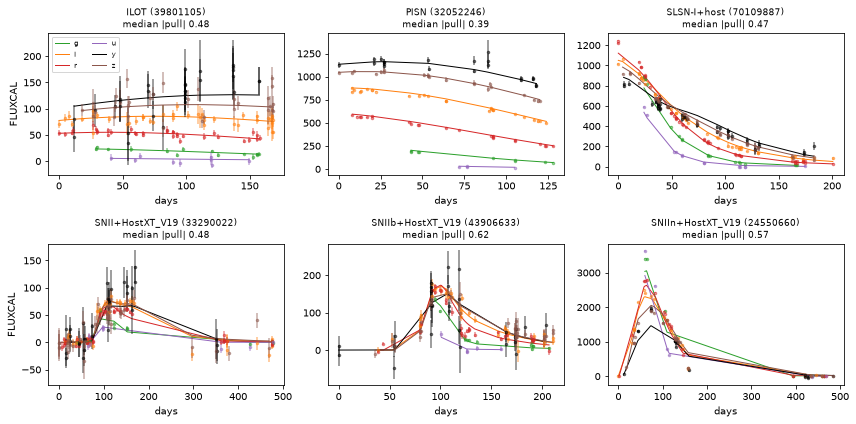

In [9]:
BAND_COLORS = {
    "u": "tab:purple",
    "g": "tab:green",
    "r": "tab:red",
    "i": "tab:orange",
    "z": "tab:brown",
    "y": "k",
}
index_band = {index: name for name, index in model.settings.band_index_map.items()}
t_max = dataset_config["flux_stats"]["t_max"]

examples = pull_sample[pull_sample["SELDON_class"].notna()].groupby("SELDON_class").head(1).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=False)
for ax, i in zip(axes.flat, examples):
    m = mask[i]
    days = (pull_batch["time_full"][i, m, 0] - pull_batch["time_full"][i, m, 0].min()) * t_max
    bands = pull_batch["band_idx_full"][i, m, 0]
    for b in np.unique(bands):
        name = index_band.get(int(b), str(b))
        color = BAND_COLORS.get(name, None)
        sel = bands == b
        ax.errorbar(
            days[sel], observed[i, m][sel], observed_error[i, m][sel], fmt="o", ms=2.5, alpha=0.5, color=color
        )
        ax.plot(days[sel], predicted[i, m][sel], "-", lw=1, color=color, label=name)
    row = pull_sample.loc[i]
    ax.set_title(
        f"{row['ELASTICC_class']} ({row['SNID']})\nmedian |pull| {row['median |pull|']:.2f}", fontsize=9
    )
    ax.set_xlabel("days")
axes.flat[0].set_ylabel("FLUXCAL")
axes.flat[3].set_ylabel("FLUXCAL")
axes.flat[0].legend(fontsize=7, ncol=2)
fig.tight_layout()

### 4. The class predictions carry information

`class_idx` comes from one posterior sample. For predictions that don't change between runs,
SELDON's energy model is evaluated at the posterior mean `z_mean` with the model's own
`predict_class`. Accuracy is over objects in the classes the run was trained on, mapped to
SELDON's classes by the run's `class_mapping`; it should be well above both the accuracy of
always guessing the most common class and that of a random guess with the same class
frequencies (the predictions shuffled between objects). The balanced accuracy is the mean over
classes of the fraction of each class predicted correctly, so it isn't dominated by the classes
with the most objects.

In [10]:
with torch.no_grad():
    z_mean = torch.as_tensor(outputs["z_mean"][[row_of[s] for s in frame["SNID"]]], device=device)
    probs = model.model.predict_class(z_mean, probs=True).cpu().numpy()

frame["predicted_at_mean"] = [
    CLASS_NAMES[i] if i < len(CLASS_NAMES) else f"index {i}" for i in probs.argmax(1)
]
frame["p_max"] = probs.max(1)
known = frame[frame["SELDON_class"].notna()]
truth = known["SELDON_class"].to_numpy()
accuracy = {
    "from a posterior sample (class_idx)": (known["predicted"].to_numpy() == truth).mean(),
    "at the posterior mean": (known["predicted_at_mean"].to_numpy() == truth).mean(),
    "at the posterior mean, balanced": known.assign(hit=known["predicted_at_mean"] == known["SELDON_class"])
    .groupby("SELDON_class")["hit"]
    .mean()
    .mean(),
    "always the most common class": known["SELDON_class"].value_counts(normalize=True).iloc[0],
    "predictions shuffled between objects": (
        np.random.default_rng(SEED).permutation(known["predicted_at_mean"].to_numpy()) == truth
    ).mean(),
}
print(f"Accuracy over the {len(known)} objects in classes SELDON was trained on:")
for name, value in accuracy.items():
    print(f"  {name:40s} {value:.3f}")
assert accuracy["at the posterior mean"] > 2 * max(
    accuracy["always the most common class"], accuracy["predictions shuffled between objects"]
)
print("PASS  well above chance")

Accuracy over the 1516 objects in classes SELDON was trained on:
  from a posterior sample (class_idx)      0.778
  at the posterior mean                    0.781
  at the posterior mean, balanced          0.796
  always the most common class             0.239
  predictions shuffled between objects     0.138
PASS  well above chance


Rows are the true SELDON class of each object (from its ELAsTiCC class), columns the class
predicted at the posterior mean; each row is normalized to 1. Note the sample has the same
number of objects per *ELAsTiCC* class, so SELDON classes made of several ELAsTiCC models
(SNII, SNIb/c, ...) have more objects.

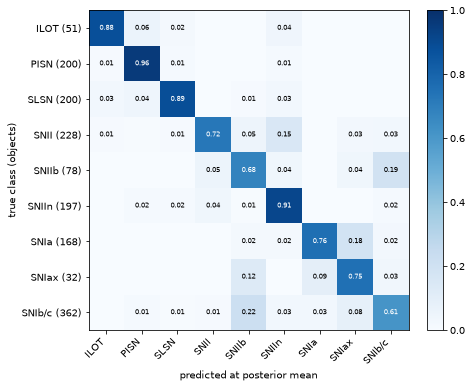

In [11]:
confusion = pd.crosstab(known["SELDON_class"], known["predicted_at_mean"], normalize="index")
confusion = confusion.reindex(
    index=[c for c in CLASS_NAMES if c in confusion.index],
    columns=CLASS_NAMES,
    fill_value=0.0,
)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(confusion.to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(confusion.columns)), confusion.columns, rotation=45, ha="right")
ax.set_yticks(range(len(confusion.index)), [f"{c} ({(truth == c).sum()})" for c in confusion.index])
for (i, j), value in np.ndenumerate(confusion.to_numpy()):
    if value >= 0.005:
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=7,
            color="white" if value > 0.5 else "black",
        )
ax.set_xlabel("predicted at posterior mean")
ax.set_ylabel("true class (objects)")
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()

## Classes SELDON was not trained on

The other ELAsTiCC classes (periodic and stochastic variables, AGN, microlensing, TDEs, ...)
still go through the model, which must call each one of its own classes. How far their
posteriors sit from the prior (the `elbo` output, a KL divergence) and how well they are
reconstructed are two ways to tell them apart from the classes the model knows.

,objects,median_elbo,most_common_prediction
ELASTICC_class,,,
CART,19,20.316399,SNIb/c
CLAGN,200,18.143599,SLSN
Cepheid,200,22.896778,SNIIn
EB,200,18.956951,SLSN
RRL,200,22.505226,ILOT
TDE,186,19.556389,SNIIn
d-Sct,200,21.863468,ILOT
uLens-Binary,54,20.694870,SLSN
uLens-Single-GenLens,80,23.063448,PISN


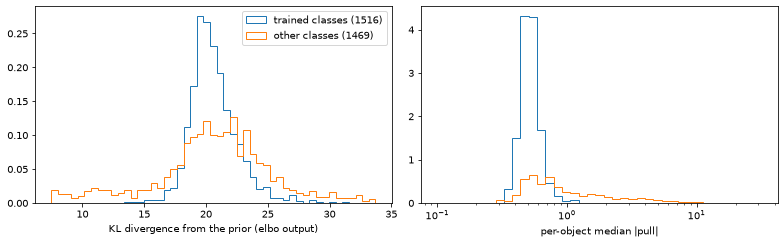

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
trained = frame["SELDON_class"].notna()
low, high = np.nanpercentile(frame["elbo"], [1, 99])
bins = np.linspace(low, high, 50)
for label, values in [
    ("trained classes", frame.loc[trained, "elbo"]),
    ("other classes", frame.loc[~trained, "elbo"]),
]:
    axes[0].hist(values, bins=bins, histtype="step", density=True, label=f"{label} ({len(values)})")
axes[0].set_xlabel("KL divergence from the prior (elbo output)")
axes[0].legend()

pull_trained = pull_sample["SELDON_class"].notna()
bins = np.logspace(-1, 1.5, 40)
for label, values in [
    ("trained classes", pull_sample.loc[pull_trained, "median |pull|"]),
    ("other classes", pull_sample.loc[~pull_trained, "median |pull|"]),
]:
    axes[1].hist(values, bins=bins, histtype="step", density=True, label=label)
axes[1].set_xscale("log")
axes[1].set_xlabel("per-object median |pull|")
fig.tight_layout()

(
    frame[~trained]
    .groupby("ELASTICC_class")
    .agg(
        objects=("SNID", "size"),
        median_elbo=("elbo", "median"),
        most_common_prediction=("predicted_at_mean", lambda s: s.value_counts().index[0]),
    )
)